# CALCE CX2 — Neural Prony added to five SOH architectures

This notebook extends the **five existing models** with a **causal, learnable exponential-memory (Neural Prony) layer**:

1. PINN–MLP + Neural Prony
2. LSTM + Neural Prony
3. LSTM–PINN + Neural Prony
4. CNN–PINN + Neural Prony
5. Transformer + Neural Prony

It also supports **all five original architectures as matched controls** and a **Transformer + fixed-timescale Prony control**. This is an *original experimental implementation*, **not an official reproduction of a published Neural Prony model**.

**Research safeguards:** use the same five selected features, battery-disjoint splits, exact same valid windows and evaluation labels, training-only normalization, no windows across removed/missing cycle ordinals, same optimizer and seeds. The optional soft monotonic penalty is a *physics-guided prior*, **not an electrochemical differential-equation PINN**. Each Prony state contains information from *previous observed cycles only* (the model also receives the current-cycle features). No recording gap is interpreted as rest.

*Target:* observed discharge-capacity SOH in fractional units. RMSE 0.0125 = **1.25 SOH percentage points**, not 0.0125%.

In [ ]:
# Uncomment and run once if needed in VS Code / Jupyter:
# %pip install torch pandas numpy matplotlib scikit-learn ipython

## 1. Paths, architecture choices, and reproducibility

In [1]:
from pathlib import Path
import os, json, math, time, random, copy, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# YOUR EXISTING WINDOWS DATA LOCATION
DATA_DIR = Path(r"C:\Projects\Battery_Soh\pre processed ready to use data")
TRAIN_FILE = "train_final_filtered.csv"   # keep unchanged originals separately
VAL_FILE = "validation.csv"
TEST_FILE = "test.csv"
OUTPUT_DIR = Path("neural_prony_five_model_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = ["cc_duration_s", "cv_duration_s", "dva_peak",
            "ic_peak_voltage", "ic_peak_width"]
TARGET = "soh"
SEQ_LEN = 12                         # later evaluate 24/48 as new experiments
HIDDEN = 64
MEMORY_DIM = 32
N_PRONY = 8                         # exponential memory channels
TAU_MIN_CYCLES = 1.0
TAU_MAX_CYCLES = 64.0

EPOCHS = 80
PATIENCE = 15
BATCH_SIZE = 128
LR = 1e-3
WEIGHT_DECAY = 1e-4
PHYSICS_WEIGHT = 0.5                # only for PINN variants
SEEDS = (42, 123, 2026)

# All five +Prony variants run by default.
# Match against all five non-Prony versions for rigorous within-notebook comparisons.
RUN_MATCHED_BASELINES = True
RUN_FIXED_PRONY_CONTROL = True       # Transformer with NON-LEARNED timescales

MAX_TRAIN_BATCHES = None            # use 2 for a quick smoke test ONLY
NUM_WORKERS = 0                     # Windows notebook multiprocessing safety
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch 2.11.0+cu128 | Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 2. Load data, verify splits, create training-only scaler

In [2]:
files = {"train": DATA_DIR / TRAIN_FILE,
         "validation": DATA_DIR / VAL_FILE, "test": DATA_DIR / TEST_FILE}
missing = {k: str(p) for k, p in files.items() if not p.is_file()}
if missing:
    raise FileNotFoundError(
        f"Missing CSVs: {missing}. Update DATA_DIR / TRAIN_FILE explicitly. "
        "Do not silently fall back to train.csv."
    )

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for part in iter(lambda: f.read(1024 * 1024), b""):
            h.update(part)
    return h.hexdigest()

def load_split(path):
    df = pd.read_csv(path)
    required = set(FEATURES + [TARGET, "battery", "cycle_ordinal"])
    if not required.issubset(df.columns):
        raise ValueError(f"Missing columns in {path}: {sorted(required-set(df.columns))}")
    if not np.isfinite(df[FEATURES + [TARGET, "cycle_ordinal"]].to_numpy(dtype=float)).all():
        raise ValueError(f"Non-finite values in {path}")
    if df.duplicated(["battery", "cycle_ordinal"]).any():
        raise ValueError(f"Repeated battery/cycle ordinals in {path}")
    return df.sort_values(["battery", "cycle_ordinal"]).reset_index(drop=True)

splits = {name: load_split(path) for name, path in files.items()}
for name, df in splits.items():
    print(f"{name:>10}: {len(df):>6} rows | batteries={sorted(df.battery.unique())}")
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    if not set(splits[left].battery).isdisjoint(set(splits[right].battery)):
        raise ValueError(f"Battery split leakage: {left} intersects {right}")

train_x = splits["train"][FEATURES].to_numpy(dtype=np.float32)
X_MEAN = train_x.mean(axis=0)
X_STD = train_x.std(axis=0)
X_STD = np.where(X_STD < 1e-8, 1.0, X_STD).astype(np.float32)
(OUTPUT_DIR / "scaler.json").write_text(json.dumps({
    "feature_order": FEATURES, "mean": X_MEAN.tolist(), "std": X_STD.tolist(),
    "fit_csv": TRAIN_FILE, "note": "fit on filtered train only"
}, indent=2), encoding="utf-8")
print("Training-only standardization ready.")

     train:   7690 rows | batteries=['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation:   1743 rows | batteries=['CX2_36']
      test:   1477 rows | batteries=['CX2_38']
Training-only standardization ready.


## 3. Causal windows — never bridge removed cycles

In [3]:
class CycleWindows(Dataset):
    """Each x uses exactly SEQ_LEN consecutive ordinals from ONE battery.

    y includes window labels for optional physics regularization but only y[-1]
    enters the supervised training loss. No model ever receives y as input.
    """
    def __init__(self, df, mean, std, seq_len):
        xx, yy, meta = [], [], []
        self.segment_lengths = []
        for battery, cell in df.groupby("battery", sort=False):
            cell = cell.sort_values("cycle_ordinal").reset_index(drop=True)
            ords = cell.cycle_ordinal.to_numpy()
            boundaries = np.r_[0, np.flatnonzero(np.diff(ords) != 1)+1, len(cell)]
            for l, r in zip(boundaries[:-1], boundaries[1:]):
                part = cell.iloc[l:r]
                self.segment_lengths.append((battery, len(part)))
                if len(part) < seq_len:
                    continue
                x = (part[FEATURES].to_numpy(dtype=np.float32) - mean) / std
                y = part[TARGET].to_numpy(dtype=np.float32)
                for j in range(seq_len - 1, len(part)):
                    xx.append(x[j-seq_len+1:j+1])
                    yy.append(y[j-seq_len+1:j+1])
                    row = part.iloc[j]
                    meta.append({"battery": str(battery),
                                 "cycle_ordinal": int(row.cycle_ordinal),
                                 "soh": float(y[j])})
        if not xx:
            raise RuntimeError(f"No consecutive {seq_len}-cycle histories. Lower SEQ_LEN.")
        self.x = torch.from_numpy(np.asarray(xx, dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(yy, dtype=np.float32))
        self.metadata = pd.DataFrame(meta)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

sets = {name: CycleWindows(df, X_MEAN, X_STD, SEQ_LEN)
        for name, df in splits.items()}
for name, d in sets.items():
    print(name, "windows", len(d), "excluded endpoints", len(splits[name])-len(d),
          "segments", len(d.segment_lengths))

# Causality/sequence sanity checks
for name, d in sets.items():
    assert d.x.shape[-2:] == (SEQ_LEN, len(FEATURES))
    assert len(d.metadata) == len(d)

def make_loaders(seed):
    generator = torch.Generator().manual_seed(seed)
    return {name: DataLoader(ds, batch_size=BATCH_SIZE,
               shuffle=(name == "train"), generator=generator if name == "train" else None,
               num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
            for name, ds in sets.items()}

train windows 3869 excluded endpoints 3821 segments 481
validation windows 918 excluded endpoints 825 segments 98
test windows 752 excluded endpoints 725 segments 92


## 4. Neural Prony memory

**Continuous-time inspiration, but discrete-cycle implementation:** state $z_{m,t}$ has one learned decay time $\tau_m$ (in **observed cycles**, *not hours*):

$$z_{m,t}=e^{-1/\tau_m}z_{m,t-1}+(1-e^{-1/\tau_m})\phi(x_t).$$

For prediction at cycle $t$, the memory emitted is $m_t=\sum_m w_m z_{m,t-1}$: **the memory uses previous observations only**; the backbone separately receives $x_t$.

- $\tau_m$ are positive and bounded to `[TAU_MIN_CYCLES, TAU_MAX_CYCLES]` using a sigmoid interpolation in log-space.
- The input feature encoder $\phi$, mixing weights, and (in learned mode) the timescales are trainable.
- Fixed-timescale control has the *same* feature encoder and mixing weights but non-trainable $\tau_m$.
- Resets to zero at the start of each window/segment; **a 12-cycle window cannot identify 64-cycle memory from outside the window**. Test longer valid windows before drawing long-memory conclusions.
- Does not treat an unobserved time gap as battery rest. In this experiment all windows consist of consecutive cycle ordinals.

In [4]:
class NeuralPronyMemory(nn.Module):
    """Finite mixture of exponential recurrent memory states, strictly causal.

    x: (batch, time, feature). Return memory BEFORE consuming current x.
    State resets per window, so there is no unavailable pre-window history.
    """
    def __init__(self, n_features, memory_dim=32, n_terms=8,
                 tau_min=1., tau_max=64., learned=True):
        super().__init__()
        if not (0 < tau_min < tau_max):
            raise ValueError("0 < tau_min < tau_max required")
        self.n_terms = n_terms
        self.memory_dim = memory_dim
        self.tau_min = tau_min
        self.tau_max = tau_max
        self.learned = learned
        self.encoder = nn.Sequential(nn.Linear(n_features, memory_dim), nn.Tanh())
        self.mix_logits = nn.Parameter(torch.zeros(n_terms))

        # Initialize log-spaced characteristic timescales within allowed range.
        initial_tau = torch.logspace(math.log10(tau_min * 1.05),
                                      math.log10(tau_max / 1.05), n_terms)
        log_min, log_max = math.log(tau_min), math.log(tau_max)
        p = ((torch.log(initial_tau) - log_min) / (log_max - log_min)).clamp(1e-4, 1-1e-4)
        if learned:
            self.tau_logits = nn.Parameter(torch.logit(p))
        else:
            self.register_buffer("tau_fixed", initial_tau)

    def timescales(self):
        if not self.learned:
            return self.tau_fixed
        return torch.exp(
            math.log(self.tau_min) + (math.log(self.tau_max)-math.log(self.tau_min))
            * torch.sigmoid(self.tau_logits)
        )

    def forward(self, x):
        B, T, _ = x.shape
        driving = self.encoder(x)  # (B,T,H)
        tau = self.timescales()
        decay = torch.exp(-1.0 / tau).view(1, self.n_terms, 1)
        mixing = torch.softmax(self.mix_logits, dim=0)
        state = x.new_zeros((B, self.n_terms, self.memory_dim))
        out = []
        for t in range(T):
            # Predict timestep t using only x[:t] for the memory channel.
            out.append(torch.einsum("bmh,m->bh", state, mixing))
            state = decay * state + (1.0-decay) * driving[:, t, :].unsqueeze(1)
        return torch.stack(out, dim=1)

# Tiny shape + causality diagnostic
_temp = NeuralPronyMemory(5, 8, 4)
_x = torch.randn(2, 6, 5)
with torch.no_grad():
    _a = _temp(_x)
    _b = _temp(torch.cat([_x[:,:3], _x[:,3:]+5], dim=1))
assert _a.shape == (2, 6, 8)
assert torch.allclose(_a[:,:4], _b[:,:4], atol=1e-6), "Prony must not see future observations"
print("Memory causal test passed; starting tau (cycles):", _temp.timescales().detach().numpy().round(2))

Memory causal test passed; starting tau (cycles): [ 1.05  4.07 15.74 60.95]


## 5. The five original architectures, with optional Neural Prony input

In [5]:
class CausalConv1d(nn.Module):
    def __init__(self, c_in, c_out, k=3, dilation=1):
        super().__init__()
        self.pad = (k - 1) * dilation
        self.conv = nn.Conv1d(c_in, c_out, kernel_size=k, dilation=dilation)
    def forward(self, x):
        return self.conv(F.pad(x, (self.pad, 0)))

class PronyAugmentedModel(nn.Module):
    def __init__(self, family, n_features=5, hidden=64,
                 prony_mode="learned", memory_dim=32, n_prony=8,
                 tau_min=1., tau_max=64.):
        super().__init__()
        if prony_mode not in {"none", "fixed", "learned"}:
            raise ValueError(prony_mode)
        self.family = family
        self.prony_mode = prony_mode
        self.prony = None if prony_mode == "none" else NeuralPronyMemory(
            n_features, memory_dim, n_prony, tau_min, tau_max,
            learned=(prony_mode == "learned"))
        d_in = n_features + (memory_dim if self.prony else 0)
        self.hidden = hidden
        if family == "pinn_mlp":
            self.backbone = nn.Sequential(nn.Linear(d_in, hidden), nn.ReLU(),
                                          nn.Linear(hidden, hidden), nn.ReLU(),
                                          nn.Linear(hidden, 1))
        elif family in {"lstm", "lstm_pinn"}:
            self.lstm = nn.LSTM(d_in, hidden, num_layers=1, batch_first=True)
            self.head = nn.Sequential(nn.Linear(hidden, hidden//2), nn.ReLU(),
                                      nn.Linear(hidden//2, 1))
        elif family == "cnn_pinn":
            self.cnn = nn.Sequential(CausalConv1d(d_in, hidden, 3, 1), nn.ReLU(),
                                     CausalConv1d(hidden, hidden, 3, 2), nn.ReLU())
            self.head = nn.Sequential(nn.Linear(hidden, hidden//2), nn.ReLU(),
                                      nn.Linear(hidden//2, 1))
        elif family == "transformer":
            self.input_layer = nn.Linear(d_in, hidden)
            self.pos = nn.Embedding(2048, hidden)
            enc = nn.TransformerEncoderLayer(d_model=hidden, nhead=4,
                 dim_feedforward=hidden*2, dropout=0.1,
                 batch_first=True, activation="gelu")
            self.transformer = nn.TransformerEncoder(enc, num_layers=2,
                                                    enable_nested_tensor=False)
            self.head = nn.Linear(hidden, 1)
        else:
            raise ValueError(f"Unknown family: {family}")

    def forward(self, x):
        if self.prony is not None:
            x = torch.cat([x, self.prony(x)], dim=-1)
        if self.family == "pinn_mlp":
            return self.backbone(x).squeeze(-1)
        if self.family in {"lstm", "lstm_pinn"}:
            return self.head(self.lstm(x)[0]).squeeze(-1)
        if self.family == "cnn_pinn":
            z = self.cnn(x.transpose(1,2)).transpose(1,2)
            return self.head(z).squeeze(-1)
        if self.family == "transformer":
            B, T, _ = x.shape
            if T > self.pos.num_embeddings:
                raise ValueError("Sequence too long for positional embedding")
            ids = torch.arange(T, device=x.device)
            z = self.input_layer(x) + self.pos(ids)[None,:,:]
            mask = torch.triu(torch.ones(T,T,dtype=torch.bool,device=x.device), diagonal=1)
            return self.head(self.transformer(z, mask=mask)).squeeze(-1)
        raise RuntimeError("Unreachable")

FAMILIES = ["pinn_mlp", "lstm", "lstm_pinn", "cnn_pinn", "transformer"]
PHYSICS_FAMILIES = {"pinn_mlp", "lstm_pinn", "cnn_pinn"}

EXPERIMENTS = [(f"{family}_prony", family, "learned") for family in FAMILIES]
if RUN_MATCHED_BASELINES:
    EXPERIMENTS += [(family, family, "none") for family in FAMILIES]
if RUN_FIXED_PRONY_CONTROL:
    EXPERIMENTS += [("transformer_prony_fixed", "transformer", "fixed")]
print("Experiments per seed:", [x[0] for x in EXPERIMENTS])

def make_model(family, mode):
    return PronyAugmentedModel(family, len(FEATURES), HIDDEN,
          mode, MEMORY_DIM, N_PRONY, TAU_MIN_CYCLES, TAU_MAX_CYCLES)

# Check shapes + causal invariance of output for eval mode
for name, family, mode in EXPERIMENTS:
    model = make_model(family, mode).eval()
    with torch.no_grad():
        x = torch.randn(2, SEQ_LEN, len(FEATURES))
        y = model(x)
        assert y.shape == (2, SEQ_LEN), (name,y.shape)
        if SEQ_LEN > 4:
            xp = x.clone(); xp[:, -1, :] += 9
            yp = model(xp)
            assert torch.allclose(y[:,:-1], yp[:,:-1], atol=1e-5), name + " uses future inputs"
    print(f"{name:>26} | trainable params = {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Experiments per seed: ['pinn_mlp_prony', 'lstm_prony', 'lstm_pinn_prony', 'cnn_pinn_prony', 'transformer_prony', 'pinn_mlp', 'lstm', 'lstm_pinn', 'cnn_pinn', 'transformer', 'transformer_prony_fixed']
            pinn_mlp_prony | trainable params = 6,865
                lstm_prony | trainable params = 28,689
           lstm_pinn_prony | trainable params = 28,689
            cnn_pinn_prony | trainable params = 21,841
         transformer_prony | trainable params = 200,721
                  pinn_mlp | trainable params = 4,609
                      lstm | trainable params = 20,289
                 lstm_pinn | trainable params = 20,289
                  cnn_pinn | trainable params = 15,489
               transformer | trainable params = 198,465
   transformer_prony_fixed | trainable params = 200,713


## 6. Loss, metrics, and model-selection rule

For every model: supervised **last-step MSE** on the same endpoint labels. The three PINN-named architectures additionally use the same soft monotonicity regularizer on within-window predictions. That prior may be violated by legitimate accessible-capacity fluctuations; compare carefully with the unregularized LSTM and Transformer.

**Model selection uses validation endpoint MSE**, not the combined physics objective; this makes validation selection comparable across models. Results from this notebook should be compared most strictly with **matched controls re-trained inside this notebook**, not necessarily the previous run with different early-stopping criteria.

In [6]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def loss_parts(pred, y, family):
    data = F.mse_loss(pred[:, -1], y[:, -1])
    phys = (F.relu(pred[:, 1:] - pred[:, :-1]).square().mean()
            if family in PHYSICS_FAMILIES else data.new_zeros(()))
    return data + PHYSICS_WEIGHT * phys, data, phys

@torch.no_grad()
def evaluate(model, loader, family):
    model.eval()
    errors, target, preds, physics_values = [], [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        out = model(xb)
        _, data, phys = loss_parts(out, yb, family)
        errors.append((float(data), len(xb)))
        physics_values.append((float(phys), len(xb)))
        target.extend(yb[:, -1].cpu().numpy())
        preds.extend(out[:, -1].cpu().numpy())
    mean_data = sum(v*n for v, n in errors) / sum(n for _,n in errors)
    mean_phys = sum(v*n for v, n in physics_values) / sum(n for _,n in physics_values)
    return mean_data, mean_phys, np.asarray(target), np.asarray(preds)

def regression_metrics(y, p):
    y, p = np.asarray(y, dtype=np.float64), np.asarray(p, dtype=np.float64)
    e = p-y
    denom = np.sum((y-y.mean())**2)
    return {
        "RMSE": float(np.sqrt(np.mean(e**2))),
        "MAE": float(np.mean(np.abs(e))),
        "MBE": float(np.mean(e)),
        "MAPE_pct": float(100*np.mean(np.abs(e)/np.maximum(np.abs(y),1e-8))),
        "R2": float(1-np.sum(e**2)/denom) if denom>0 else float("nan")
    }

def save_prediction_file(split, experiment, seed, actual, predicted):
    table = sets[split].metadata.copy()
    assert np.allclose(table.soh.to_numpy(), actual, atol=1e-6)
    table["predicted_soh"] = predicted
    table["error_soh"] = predicted - actual
    table.to_csv(OUTPUT_DIR / f"{experiment}_seed{seed}_{split}_predictions.csv", index=False)

## 7. Train, early-stop, checkpoint, and export predictions

In [7]:
def train_one(experiment, family, mode, seed):
    set_seed(seed)
    model = make_model(family, mode).to(DEVICE)
    optim = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loaders = make_loaders(seed)
    best = float("inf")
    best_epoch, best_weights, bad_epochs = 0, None, 0
    history = []
    start = time.perf_counter()

    for epoch in range(1, EPOCHS+1):
        model.train()
        steps = []
        for bidx, (xb, yb) in enumerate(loaders["train"]):
            if MAX_TRAIN_BATCHES is not None and bidx >= MAX_TRAIN_BATCHES:
                break
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad(set_to_none=True)
            out = model(xb)
            total, mse, phys = loss_parts(out, yb, family)
            if not torch.isfinite(total):
                raise FloatingPointError(f"Nonfinite loss {experiment}, seed {seed}, epoch {epoch}")
            total.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.)
            optim.step()
            steps.append((float(total.detach()), float(mse.detach()),
                          float(phys.detach()), len(xb)))

        train_mse = sum(a[1]*a[3] for a in steps)/sum(a[3] for a in steps)
        train_phys = sum(a[2]*a[3] for a in steps)/sum(a[3] for a in steps)
        val_mse, val_phys, _, _ = evaluate(model, loaders["validation"], family)
        history.append({"epoch":epoch, "train_MSE":train_mse,
                        "train_physics":train_phys, "validation_MSE":val_mse,
                        "validation_physics":val_phys})
        if val_mse < best - 1e-9:
            best = val_mse
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            bad_epochs = 0
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                break
        if epoch == 1 or epoch % 10 == 0:
            print(f"{experiment} | seed {seed} | epoch {epoch} | val RMSE {math.sqrt(val_mse):.5f}")

    model.load_state_dict(best_weights)
    duration = time.perf_counter() - start
    weights_path = OUTPUT_DIR / f"{experiment}_seed{seed}.pt"
    torch.save({"state_dict":model.state_dict(), "experiment":experiment,
                "family":family, "prony_mode":mode, "seed":seed,
                "features":FEATURES, "seq_len":SEQ_LEN,
                "normalization_mean":X_MEAN.tolist(),
                "normalization_std":X_STD.tolist(),
                "physics_weight": PHYSICS_WEIGHT}, weights_path)
    pd.DataFrame(history).to_csv(
        OUTPUT_DIR / f"{experiment}_seed{seed}_history.csv", index=False)

    if model.prony is not None:
        taus = model.prony.timescales().detach().cpu().numpy()
        weights = torch.softmax(model.prony.mix_logits,0).detach().cpu().numpy()
        pd.DataFrame({"term":np.arange(1,len(taus)+1),
                      "tau_cycles":taus, "mix_weight":weights,
                      "learned_timescale":mode == "learned"}).to_csv(
            OUTPUT_DIR / f"{experiment}_seed{seed}_prony_timescales.csv",index=False)

    rows = []
    # Evaluation must be UNSHUFFLED for the prediction arrays to align with metadata.
    # Training still uses a shuffled loader; all split predictions are saved in dataset order.
    eval_loaders = {name: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
                    for name, ds in sets.items()}
    for split, loader in eval_loaders.items():
        mse, phys, true, pred = evaluate(model, loader, family)
        save_prediction_file(split, experiment, seed, true, pred)
        rows.append({"model":experiment, "architecture":family,
                     "prony_mode":mode, "seed":seed, "split":split,
                     "n_windows":len(true), "best_epoch":best_epoch,
                     "epochs_trained":len(history), "training_seconds":duration,
                     "parameters":sum(p.numel() for p in model.parameters() if p.requires_grad),
                     "data_MSE":mse,"physics_loss":phys,
                     **regression_metrics(true,pred)})
    return rows

## 8. Run experiments

This runs **5 Neural Prony variants + 5 non-Prony matched controls + 1 fixed-timescale control**, at all selected seeds. For a quick sanity check use `SEEDS=(42,)`, `EPOCHS=1`, `MAX_TRAIN_BATCHES=2`, `RUN_MATCHED_BASELINES=False` and restore values before research reporting. The notebook **does not claim any improvement until your training completes**.

In [8]:
settings = {
    "csv_paths": {k:str(v) for k,v in files.items()},
    "input_sha256": {k:file_sha256(v) for k,v in files.items()},
    "features":FEATURES, "target":TARGET, "seq_len":SEQ_LEN,
    "hidden":HIDDEN, "memory_dim":MEMORY_DIM, "n_prony":N_PRONY,
    "tau_min_cycles":TAU_MIN_CYCLES, "tau_max_cycles":TAU_MAX_CYCLES,
    "epochs":EPOCHS, "patience":PATIENCE, "batch_size":BATCH_SIZE,
    "lr":LR, "weight_decay":WEIGHT_DECAY,
    "physics_weight":PHYSICS_WEIGHT, "seeds":list(SEEDS),
    "max_train_batches":MAX_TRAIN_BATCHES, "device":str(DEVICE),
    "window_counts":{k:len(v) for k,v in sets.items()},
    "experiments": [{"name":n,"family":f,"mode":m} for n,f,m in EXPERIMENTS],
    "target_protocol":"current endpoint measured SOH; exact consecutive-cycle windows",
    "selection":"minimum validation endpoint MSE"
}
(OUTPUT_DIR / "experiment_config.json").write_text(json.dumps(settings,indent=2),encoding="utf-8")

all_records = []
for experiment, family, mode in EXPERIMENTS:
    for seed in SEEDS:
        print("\n===", experiment, "seed", seed, "===")
        run_rows = train_one(experiment,family,mode,seed)
        all_records.extend(run_rows)
        pd.DataFrame(all_records).to_csv(OUTPUT_DIR/"metrics_all_runs.csv",index=False)

results = pd.DataFrame(all_records)
display(results.query('split == "test"').sort_values("RMSE")[
    ["model","seed","RMSE","MAE","MAPE_pct","R2","best_epoch"]])


=== pinn_mlp_prony seed 42 ===
pinn_mlp_prony | seed 42 | epoch 1 | val RMSE 0.22821
pinn_mlp_prony | seed 42 | epoch 10 | val RMSE 0.03086
pinn_mlp_prony | seed 42 | epoch 20 | val RMSE 0.02340
pinn_mlp_prony | seed 42 | epoch 30 | val RMSE 0.01784
pinn_mlp_prony | seed 42 | epoch 40 | val RMSE 0.01540
pinn_mlp_prony | seed 42 | epoch 50 | val RMSE 0.00990
pinn_mlp_prony | seed 42 | epoch 60 | val RMSE 0.01173
pinn_mlp_prony | seed 42 | epoch 70 | val RMSE 0.00839
pinn_mlp_prony | seed 42 | epoch 80 | val RMSE 0.00984

=== pinn_mlp_prony seed 123 ===
pinn_mlp_prony | seed 123 | epoch 1 | val RMSE 0.18205
pinn_mlp_prony | seed 123 | epoch 10 | val RMSE 0.01507
pinn_mlp_prony | seed 123 | epoch 20 | val RMSE 0.01265
pinn_mlp_prony | seed 123 | epoch 30 | val RMSE 0.01119
pinn_mlp_prony | seed 123 | epoch 40 | val RMSE 0.01108
pinn_mlp_prony | seed 123 | epoch 50 | val RMSE 0.00963
pinn_mlp_prony | seed 123 | epoch 60 | val RMSE 0.00960

=== pinn_mlp_prony seed 2026 ===
pinn_mlp_prony |

,model,seed,RMSE,MAE,MAPE_pct,R2,best_epoch
86,transformer,123,0.009872,0.008870,1.127757,0.993740,26
44,transformer_prony,2026,0.011180,0.010114,1.297793,0.991971,24
98,transformer_prony_fixed,2026,0.011190,0.010117,1.298051,0.991957,24
20,lstm_pinn_prony,42,0.013401,0.011529,1.555813,0.988463,43
89,transformer,2026,0.013408,0.012420,1.552182,0.988453,20
95,transformer_prony_fixed,123,0.013417,0.011762,1.636561,0.988437,39
41,transformer_prony,123,0.013426,0.011776,1.638117,0.988422,39
32,cnn_pinn_prony,123,0.014120,0.012366,1.605434,0.987193,75
23,lstm_pinn_prony,123,0.014431,0.013755,1.765580,0.986622,77
65,lstm_pinn,42,0.014685,0.012613,1.711981,0.986148,44


## 9. Aggregate metrics; rank by validation (test is for reporting)

In [9]:
summary = (results.groupby(["split","model","architecture","prony_mode"])
   .agg(RMSE_mean=("RMSE","mean"), RMSE_std=("RMSE","std"),
        MAE_mean=("MAE","mean"),MAE_std=("MAE","std"),
        MAPE_mean=("MAPE_pct","mean"),
        R2_mean=("R2","mean"),
        train_seconds_mean=("training_seconds","mean"),
        parameters=("parameters","first"),
        n_seeds=("seed","nunique"))
   .reset_index())
summary.to_csv(OUTPUT_DIR / "metrics_summary.csv",index=False)
print("Validation leaderboard (use to select models):")
display(summary.query('split == "validation"').sort_values('RMSE_mean'))
print("Held-out test reporting (do not use for tuning):")
display(summary.query('split == "test"').sort_values('RMSE_mean'))

Validation leaderboard (use to select models):


,split,model,architecture,prony_mode,RMSE_mean,RMSE_std,MAE_mean,MAE_std,MAPE_mean,R2_mean,train_seconds_mean,parameters,n_seeds
30,validation,transformer,transformer,none,0.007066,0.001071,0.005634,0.001014,0.784512,0.996564,21.413843,198465,3
31,validation,transformer_prony,transformer,learned,0.007456,0.001472,0.005444,0.001054,0.777596,0.996134,62.942275,200721,3
32,validation,transformer_prony_fixed,transformer,fixed,0.007461,0.001476,0.005448,0.001059,0.778111,0.996128,72.887243,200713,3
29,validation,pinn_mlp_prony,pinn_mlp,learned,0.008565,0.001661,0.005802,0.000795,0.840099,0.994904,147.250542,6865,3
26,validation,lstm_pinn_prony,lstm_pinn,learned,0.009270,0.004566,0.006367,0.002765,0.933964,0.993234,78.600716,28689,3
25,validation,lstm_pinn,lstm_pinn,none,0.009554,0.002151,0.006270,0.001341,0.933433,0.993605,26.797400,20289,3
27,validation,lstm_prony,lstm,learned,0.012052,0.005041,0.008046,0.003055,1.202272,0.989007,76.519618,28689,3
24,validation,lstm,lstm,none,0.012255,0.002103,0.008204,0.001182,1.236521,0.989621,29.221872,20289,3
23,validation,cnn_pinn_prony,cnn_pinn,learned,0.012805,0.003842,0.009007,0.002832,1.344533,0.988220,121.077080,21841,3
28,validation,pinn_mlp,pinn_mlp,none,0.015515,0.003525,0.010332,0.002396,1.571756,0.983125,17.995922,4609,3


Held-out test reporting (do not use for tuning):


,split,model,architecture,prony_mode,RMSE_mean,RMSE_std,MAE_mean,MAE_std,MAPE_mean,R2_mean,train_seconds_mean,parameters,n_seeds
8,test,transformer,transformer,none,0.012754,0.002618,0.011458,0.002266,1.427462,0.989257,21.413843,198465,3
9,test,transformer_prony,transformer,learned,0.013571,0.002467,0.012233,0.002380,1.649730,0.987908,62.942275,200721,3
10,test,transformer_prony_fixed,transformer,fixed,0.013572,0.002464,0.012230,0.002381,1.649382,0.987907,72.887243,200713,3
4,test,lstm_pinn_prony,lstm_pinn,learned,0.014476,0.001097,0.012918,0.001211,1.731884,0.986488,78.600716,28689,3
3,test,lstm_pinn,lstm_pinn,none,0.015159,0.000593,0.013259,0.000695,1.789106,0.985225,26.797400,20289,3
7,test,pinn_mlp_prony,pinn_mlp,learned,0.015750,0.000989,0.014324,0.001219,1.849859,0.984023,147.250542,6865,3
2,test,lstm,lstm,none,0.017813,0.001030,0.016343,0.000633,2.199678,0.979572,29.221872,20289,3
1,test,cnn_pinn_prony,cnn_pinn,learned,0.018105,0.005037,0.016337,0.004868,2.183226,0.977857,121.077080,21841,3
5,test,lstm_prony,lstm,learned,0.018244,0.003011,0.016797,0.002761,2.252069,0.978231,76.519618,28689,3
0,test,cnn_pinn,cnn_pinn,none,0.021485,0.007292,0.018326,0.005089,2.455112,0.968071,60.496461,15489,3


## 10. Matched paired comparisons: does Prony help?

In [10]:
comparisons = []
for family in FAMILIES:
    vanilla = family
    learned = f"{family}_prony"
    for seed in SEEDS:
        rows_a = results[(results.model==vanilla)&(results.seed==seed)&(results.split=="validation")]
        rows_b = results[(results.model==learned)&(results.seed==seed)&(results.split=="validation")]
        if len(rows_a)==1 and len(rows_b)==1:
            a,b = rows_a.iloc[0],rows_b.iloc[0]
            comparisons.append({"family":family,"seed":seed,
              "baseline_val_RMSE":a.RMSE,"prony_val_RMSE":b.RMSE,
              "relative_improvement_pct":100*(a.RMSE-b.RMSE)/a.RMSE})
paired = pd.DataFrame(comparisons)
paired.to_csv(OUTPUT_DIR / "paired_validation_improvements.csv", index=False)
if not paired.empty:
    display(paired)
else:
    print("Enable RUN_MATCHED_BASELINES for paired comparisons.")

# Validate learned vs fixed timescales on identical backbone, as a separate control.
fixed = summary[(summary.split=="validation")&
                (summary.model.isin(["transformer_prony", "transformer_prony_fixed"]))]
if len(fixed):
    print("Transformer learned-vs-fixed tau (validation only):")
    display(fixed[["model","RMSE_mean","RMSE_std","parameters"]])

,family,seed,baseline_val_RMSE,prony_val_RMSE,relative_improvement_pct
0,pinn_mlp,42,0.012084,0.007325,39.387507
1,pinn_mlp,123,0.015332,0.007917,48.361109
2,pinn_mlp,2026,0.019128,0.010452,45.358844
3,lstm,42,0.013925,0.009068,34.876506
4,lstm,123,0.012947,0.009216,28.820461
5,lstm,2026,0.009894,0.017873,-80.643798
6,lstm_pinn,42,0.011760,0.007511,36.127587
7,lstm_pinn,123,0.009439,0.005846,38.068333
8,lstm_pinn,2026,0.007462,0.014454,-93.695890
9,cnn_pinn,42,0.024516,0.013631,44.400638


Transformer learned-vs-fixed tau (validation only):


,model,RMSE_mean,RMSE_std,parameters
31,transformer_prony,0.007456,0.001472,200721
32,transformer_prony_fixed,0.007461,0.001476,200713


## 11. Plot held-out test predictions and validation loss curves

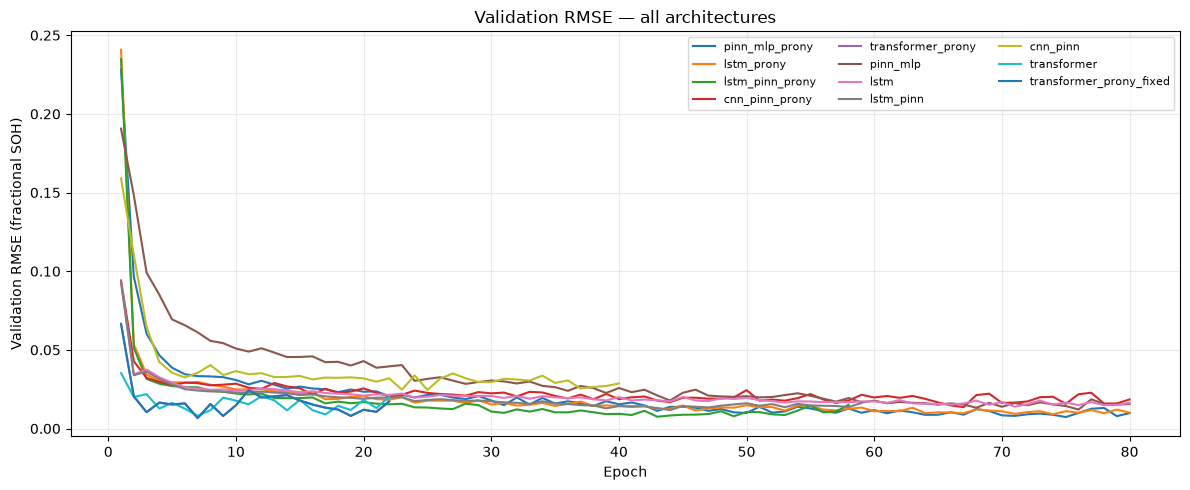

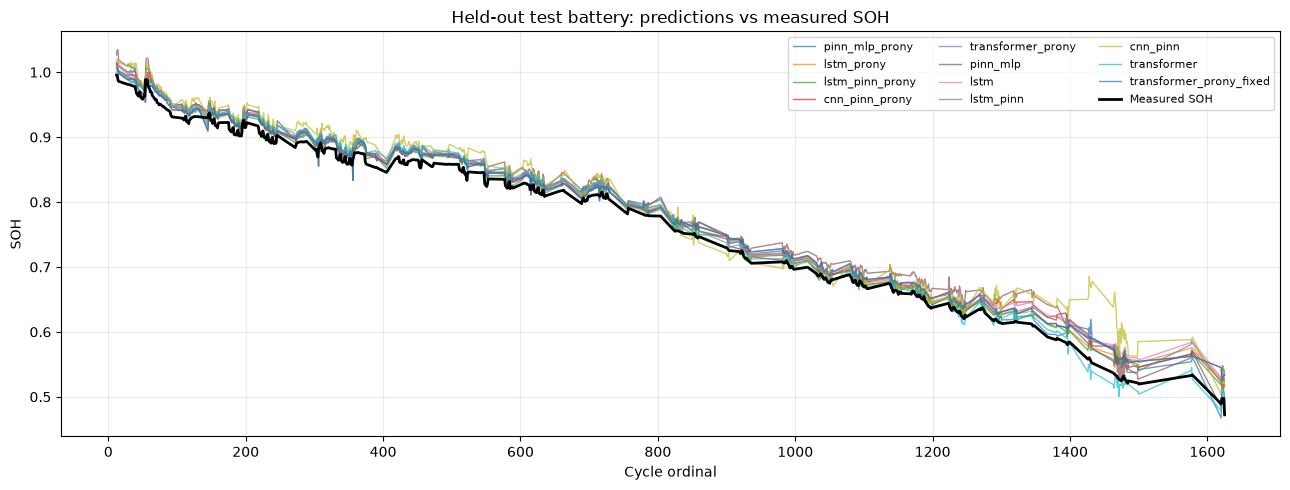

In [11]:
plt.figure(figsize=(12,5))
for experiment, family, mode in EXPERIMENTS:
    hist = pd.read_csv(OUTPUT_DIR/f"{experiment}_seed{SEEDS[0]}_history.csv")
    plt.plot(hist.epoch, np.sqrt(hist.validation_MSE), label=experiment)
plt.xlabel("Epoch"); plt.ylabel("Validation RMSE (fractional SOH)")
plt.title("Validation RMSE — all architectures")
plt.grid(alpha=.25); plt.legend(ncol=3,fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"validation_rmse_curves.png",dpi=180)
plt.show()

plt.figure(figsize=(13,5))
for experiment, family, mode in EXPERIMENTS:
    d = pd.read_csv(OUTPUT_DIR/f"{experiment}_seed{SEEDS[0]}_test_predictions.csv")
    d = d.sort_values(["battery","cycle_ordinal"])
    plt.plot(d.cycle_ordinal, d.predicted_soh, label=experiment,alpha=.7,linewidth=1)
plt.plot(d.cycle_ordinal, d.soh, label="Measured SOH",color="black",linewidth=2)
plt.xlabel("Cycle ordinal"); plt.ylabel("SOH")
plt.title("Held-out test battery: predictions vs measured SOH")
plt.grid(alpha=.25); plt.legend(ncol=3,fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"test_predictions.png",dpi=180)
plt.show()

## 12. Examine learned timescales and whether they collapse

min    median        max
model                   seed                               
cnn_pinn_prony          42    1.052984  8.275819  60.942104
                        123   1.054853  8.240715  60.921910
                        2026  1.052196  8.281109  60.926094
lstm_pinn_prony         42    1.070252  8.318913  60.882240
                        123   1.069787  8.382430  60.891243
                        2026  1.067792  8.263024  60.885260
lstm_prony              42    1.048183  8.084327  60.861343
                        123   1.048996  8.096599  60.861195
                        2026  1.049123  8.171113  60.890633
pinn_mlp_prony          42    1.076042  8.281758  60.895863
                        123   1.055087  8.204315  60.902275
                        2026  1.065455  8.229023  60.897835
transformer_prony       42    1.049854  8.429163  60.982918
                        123   1.050767  8.433023  60.984140
                        2026  1.051155  8.565859  61.026580
transformer_prony_fixed 42    1.050000  8.338983  60.952380
                        123   1.050000  8.338983  60.952380
                        2026  1.050000  8.338983  60.952380

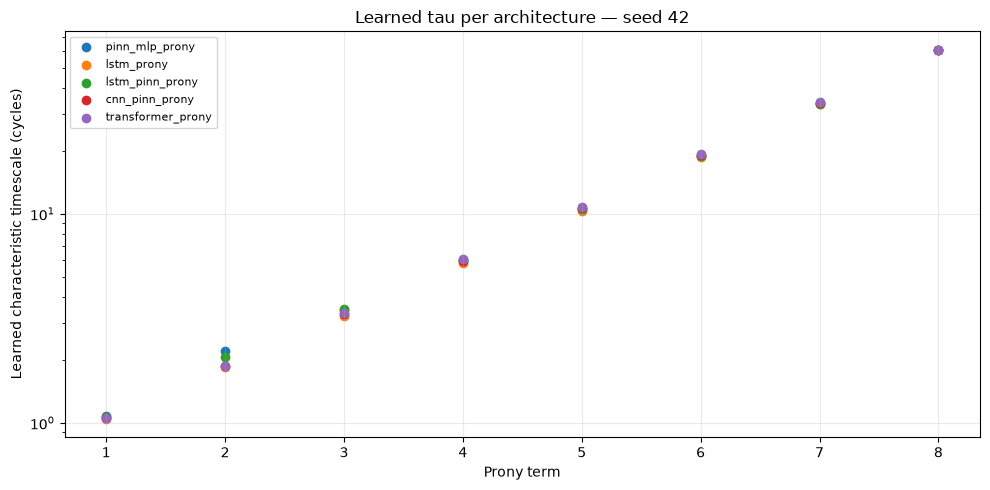

In [12]:
tau_rows = []
for experiment, family, mode in EXPERIMENTS:
    if mode == "none":
        continue
    for seed in SEEDS:
        f = OUTPUT_DIR/f"{experiment}_seed{seed}_prony_timescales.csv"
        t = pd.read_csv(f)
        t["model"] = experiment
        t["seed"] = seed
        tau_rows.append(t)
if tau_rows:
    tau_all = pd.concat(tau_rows, ignore_index=True)
    tau_all.to_csv(OUTPUT_DIR/"prony_timescales_all.csv",index=False)
    display(tau_all.groupby(["model","seed"])["tau_cycles"].agg(["min","median","max"]))
    fig, ax = plt.subplots(figsize=(10,5))
    first_seed = SEEDS[0]
    for name in [f"{f}_prony" for f in FAMILIES]:
        part=tau_all[(tau_all.model==name)&(tau_all.seed==first_seed)]
        ax.scatter(part.term,part.tau_cycles,label=name)
    ax.set_yscale("log")
    ax.set(xlabel="Prony term",ylabel="Learned characteristic timescale (cycles)",
           title=f"Learned tau per architecture — seed {first_seed}")
    ax.grid(alpha=.25); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUTPUT_DIR/"learned_prony_timescales.png",dpi=180)
    plt.show()

## 13. Notes for a defensible research comparison

- **These are five *Prony-augmented* variants, not five proven superior models.** We must compare against all five matched no-Prony models and the Transformer fixed-timescale control.
- **Additional parameters:** Prony models have more parameters. Report parameter counts and wall time, and consider a width-matched control if improvements are small.
- **Same information:** All models use the five selected features. Prony adds memory of *past values of these features*, not extra measured sensors.
- **Current-cycle availability:** This predicts SOH after the current cycle's charging indicators have been observed; it is **estimation**, not future-cycle forecasting.
- **Physics:** PINN variants use only a monotonic-prediction penalty. Measured SOH can jump; this prior might be wrong on some observations and should be ablated.
- **Sequence truncation:** Memory is reset at each 12-cycle window. A learned 64-cycle tau does not establish useful 64-cycle memory; repeat with longer windows and adequate coverage.
- **Rest/gap uncertainty:** Consecutive cycle ordinals do not prove an uninterrupted operating history or rest. No inference of rest is made here.
- **Filtering:** The experimental filtered training CSV excludes flagged jumps, not verified errors. Preserve the original unfiltered train file and document the criterion.
- **Model selection:** Keep the test battery held out. Tune hyperparameters using *validation* only; eventually repeat leave-one-battery-out evaluations.
- **Pretrained baseline numbers:** The matched baseline results may differ from previously reported scores because early stopping selects by validation MSE, and this notebook refits its scaler on the filtered training file.